### 🌾**Deep Learning for Well-watered & Drought Stress Maize Images**

__Base Model for Comparison - MobileNetV2__

Input Images Source: https://zenodo.org/records/10991581

Description:
- Acts as benchmarking model using MobileNetV2 against custom 2D CNN Models for maize images water stress classification (i.e., Dought vs Watered)
- MobileNetV2 architecture configured with ImageNet weights with trainable set to true to enable fine-tuning using training dataset
- Dense layers & dropout applied are identical to 2D CNN custom models for controlled head architecture
- Learning rate used is much lower (1e-5) due to extreme fluctuations observed at 1e-3
---


Resources:
1. mobilenet-v2-1.0-224
https://docs.openvino.ai/2023.3/omz_models_model_mobilenet_v2_1_0_224.html

In [1]:
import numpy as np
from pathlib import Path
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import time
from tensorflow.keras.layers import MaxPooling2D, Dense, Dropout
from tensorflow.keras import regularizers
import math

# from google.colab import drive 
from pathlib import Path

# Set random seed for reproducibility
SEED_SIZE = 42
keras.utils.set_random_seed(SEED_SIZE)

# Restart Keras session to clear previous instances
keras.backend.clear_session()

# Initialize Seaborn theme
sns.set_theme(style='darkgrid')

plt.rcParams.update({
    'font.family': 'monospace',
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})


In [2]:
"""---------------------------------
Connect to Folder Path Containing Train, Test & Validation Images
------------------------------------"""
DATA_ROOT = Path("maize_watered_drought_sorted")

In [3]:
"""---------------------------------
Load & Create train-test-val data sets
------------------------------------"""

BATCH_SIZE = 64
IMAGE_SIZE = (168, 224)

# Predefined classes to ensure consistency in encoding during model training & validation
CLASSES = ['Drought_Trial001_2', 'Watered_Trial001_1']

train_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT / "train",
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    color_mode='rgb',
    shuffle=True,
    seed=SEED_SIZE
)

validation_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT / "validation",
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    color_mode='rgb',
    shuffle=False,

)

test_ds = keras.utils.image_dataset_from_directory(
    DATA_ROOT / "test",
    image_size=IMAGE_SIZE,
    batch_size=None,
    label_mode="binary",
    class_names=CLASSES,
    color_mode='rgb',
    shuffle=False
)

# Verify training dataset sample size for each class
class_counts = {cls: 0 for cls in train_ds.class_names}
for image, label in train_ds:
    label_val = label.numpy()
    if label_val.ndim > 0:
        label_val = label_val.item()
        
    class_idx = int(label_val)
    class_name = train_ds.class_names[class_idx]
    class_counts[class_name] += 1

print("Class sample counts:", class_counts)

Found 3678 files belonging to 2 classes.
Found 788 files belonging to 2 classes.
Found 789 files belonging to 2 classes.
Class sample counts: {'Drought_Trial001_2': 1864, 'Watered_Trial001_1': 1814}


In [4]:
"""---------------------------------
Dataset Normalization & Optimization of TensorFlow Pipeline
------------------------------------"""

AUTOTUNE = tf.data.AUTOTUNE

validation_ds = validation_ds.cache()
validation_ds = validation_ds.batch(BATCH_SIZE)
validation_ds = validation_ds.prefetch(buffer_size=AUTOTUNE)

test_ds = test_ds.cache()
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

train_ds = train_ds.cache()
train_ds = train_ds.shuffle(2000, seed=SEED_SIZE)
train_ds = train_ds.batch(BATCH_SIZE, drop_remainder=True)
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)

In [5]:
"""---------------------------------
Model 2 - MobileNetV2
------------------------------------"""
trainingtime_start = time.perf_counter() # Start time counter

INPUT_SHAPE = (168, 224, 3)

# Use pre-trained MobileNetV2 with trainable features for fine tuning
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=INPUT_SHAPE)
base_model.trainable = True

model = Sequential([
    layers.Input(shape=INPUT_SHAPE),
    layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),

    base_model,
    
    layers.GlobalAveragePooling2D(),
    Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(1, activation='sigmoid', dtype='float32',  kernel_initializer='glorot_uniform')
])


C:\Users\ptong\AppData\Local\Temp\ipykernel_38444\67860743.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=INPUT_SHAPE)


In [6]:
"""---------------------------------
Model Fitting
------------------------------------"""

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # lower learning rate to reduce fluctuations
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30
)

# Compute training time
trainingtime_end = time.perf_counter()
training_duration = trainingtime_end - trainingtime_start

print(f"Training Time: {training_duration:.4f} seconds")

Epoch 1/30


c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.6478 - loss: 0.6448 - val_accuracy: 0.5381 - val_loss: 0.7725
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.8829 - loss: 0.3607 - val_accuracy: 0.6536 - val_loss: 0.6919
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.9605 - loss: 0.1923 - val_accuracy: 0.6459 - val_loss: 0.6298
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9775 - loss: 0.1203 - val_accuracy: 0.7043 - val_loss: 0.5635
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.9912 - loss: 0.0747 - val_accuracy: 0.7563 - val_loss: 0.4903
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.9959 - loss: 0.0530 - val_accuracy: 0.7817 - val_loss: 0.4459
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.9964 - loss: 0.0410 - val_accuracy: 0.8350 - val_loss: 0.3620
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.9978 - loss: 0.0330 - val_accuracy: 0.8579 - val_loss: 0.3280
Epo

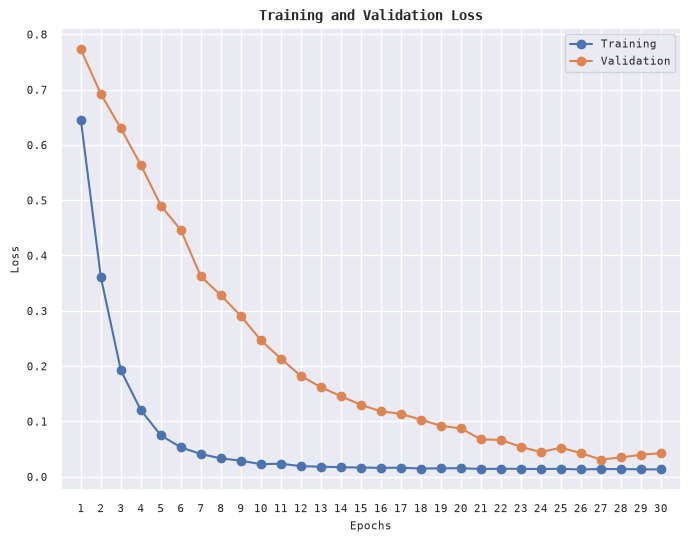

In [9]:
"""---------------------------------
Generating Epochs vs Error Plot
------------------------------------"""
x_data = range(1, len(history.history['loss']) + 1)
plt.figure(figsize=(8,6))
plt.plot(x_data, history.history['loss'], label='Training', marker='o')
plt.plot(x_data, history.history['val_loss'], label='Validation', marker='o')

plt.xlim(0, len(history.history['loss']) + 1)
plt.xticks(range(1, len(history.history['loss']) + 1))
plt.xlabel('Epochs', fontsize=8)
plt.ylabel('Loss', fontsize=8)
plt.grid(True, linestyle='-', linewidth=1)
plt.title('Training and Validation Loss', fontsize=10, fontweight='bold')
plt.legend(fontsize=8)
plt.show()


Accuracy: 0.9911
precision: 0.9848
recall: 0.9974
f1: 0.9911
Confusion Matrix:
[[394   6]
 [  1 388]]


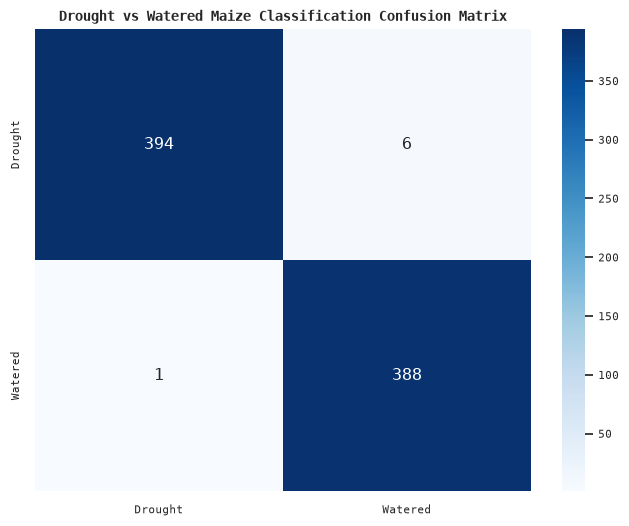

In [ ]:
"""---------------------------------
Summary Results
------------------------------------"""

test_ypred_raw = model.predict(test_ds, verbose=0).flatten()
test_ytrue = np.concatenate([y.numpy() for _, y in test_ds], axis=0).flatten().astype(int)
test_ypred = (test_ypred_raw >= 0.5).astype(int)

# Extract ground truth labels & convert to 1D numpy array of intergers
test_conmat = confusion_matrix(test_ytrue, test_ypred)

# Compute for accuracy, precision, recall and F1 score
accuracy = accuracy_score(test_ytrue, test_ypred)
precision = precision_score(test_ytrue, test_ypred, zero_division=0)
recall = recall_score(test_ytrue, test_ypred, zero_division=0)
f1 = f1_score(test_ytrue, test_ypred, zero_division=0)

print(f'Accuracy: {round((accuracy),4)}')
print(f'precision: {round((precision),4)}')
print(f'recall: {round((recall),4)}')
print(f'f1: {round((f1),4)}')
print(f'Confusion Matrix:\n{test_conmat}')

# Define class names for Confusion Matrix
class_names = ['Drought', 'Watered'] 

# Generate Confusion Matrix Chart
plt.figure(figsize=(8, 6))
sns.heatmap(test_conmat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Drought vs Watered Maize Classification Confusion Matrix", fontsize=10, fontweight='bold')
plt.show()